# QuickKart Customers: Solution and Explanation
**ICT Academy of Kerala · Session 42 · Use-Case Discussion: Handling Missing Values & Duplicates · Solution notebook (shared after submission)**

**How to use this notebook:** compare it with your own work. It shows **one good way** to explore `quickkart_customers.csv` (1500 rows, 10 columns) using what was taught in the Session 42 class (finding missing values, finding and removing duplicates) and earlier classes (pandas, descriptive statistics, Matplotlib/Seaborn). Your steps may be different and that is fine. What matters is that every decision has a **reason**.

**Scenario:** QuickKart, an online store in Kerala, merged its customer files from several systems. Management wants a clean file for reporting. *Explore, clean and justify.*

**Map of exploration to classes**
| Section | What is explored | Class it comes from |
|---|---|---|
| 1 | shape, head, tail, info, dtypes | pandas basics |
| 2 | mean, median, mode, std, range, skew | descriptive statistics |
| 3 | value_counts, unique values of text columns | pandas, dictionaries / strings |
| 4 | missing values: count, %, pattern | **today** |
| 5 | duplicates | **today** |
| 6 | wrong values and messy text | pandas, strings, data thinking |
| 7 | plots: hist, box, count, heatmap | Matplotlib / Seaborn |
| 8 | relations: groupby, pivot, correlation | pandas, statistics |
| 9 | removing duplicates and fixing spelling | **today** |
| 10 | before vs after | pandas |

> **What is not in this section:** *filling the missing values*, *fixing impossible values* and *box plots* were taught in the Session 43 class, after this use-case. They are solved in the **Session 44 section** at the end of this notebook.

## 0 · Load the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)

df = pd.read_csv("quickkart_customers.csv")
raw = df.copy()          # untouched copy for before / after
print("Loaded:", df.shape)

Loaded: (1500, 10)


## 1 · First look  *(pandas basics)*

In [2]:
print(df.head())
print()
print(df.tail(3))

  Customer_ID   Age  Gender       City Membership      Payment_Mode  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
0       C0258  29.0  Female  Kozhikode      Basic        Debit Card         55900.0               6.0            523.0       3143.0
1       C0758  36.0    Male   Thrissur     Silver               UPI         47900.0              21.0            855.0      16395.0
2       C0993  18.0    Male   Thrissur      Basic               UPI         32600.0               2.0            491.0       1007.0
3       C1171  32.0  Female      Kochi       Gold       Credit Card         32900.0              12.0           1776.0      22554.0
4       C1069  34.0  Female      Kochi       Gold  Cash on Delivery         81000.0              10.0            426.0       3915.0

     Customer_ID   Age  Gender      City Membership Payment_Mode  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
1497       C0639  24.0    Male     Kochi      Basic          UPI         45200

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1500 non-null   str    
 1   Age               1419 non-null   float64
 2   Gender            1449 non-null   str    
 3   City              1434 non-null   str    
 4   Membership        1500 non-null   str    
 5   Payment_Mode      1405 non-null   str    
 6   Monthly_Income    1346 non-null   float64
 7   Orders_Last_Year  1500 non-null   float64
 8   Avg_Order_Value   1376 non-null   float64
 9   Total_Spent       1500 non-null   float64
dtypes: float64(5), str(5)
memory usage: 117.3 KB


In [4]:
print(df.dtypes)
print()
print("Unique values per column:")
print(df.nunique())

Customer_ID             str
Age                 float64
Gender                  str
City                    str
Membership              str
Payment_Mode            str
Monthly_Income      float64
Orders_Last_Year    float64
Avg_Order_Value     float64
Total_Spent         float64
dtype: object

Unique values per column:
Customer_ID         1465
Age                   51
Gender                 5
City                  17
Membership             9
Payment_Mode           5
Monthly_Income       548
Orders_Last_Year      40
Avg_Order_Value      799
Total_Spent         1359
dtype: int64


## 2 · Descriptive statistics  *(central tendency and dispersion classes)*
You can compare **mean vs median** and look at the range and spread of every number column.

In [5]:
print(df.describe().round(1))

          Age  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
count  1419.0          1346.0            1500.0           1376.0       1500.0
mean     34.2         43418.4               9.0            817.3       5723.8
std      10.6         62967.8              15.6           1805.3       6497.8
min      -3.0          5500.0               1.0             81.0        157.0
25%      27.0         24100.0               4.0            401.0       1937.8
50%      34.0         33600.0               7.0            579.5       3820.5
75%      41.0         47300.0              11.0            868.2       7280.2
max     150.0        900000.0             310.0          35000.0      85073.0


In [6]:
num = ["Age", "Monthly_Income", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent"]
stats = pd.DataFrame({"mean": df[num].mean(), "median": df[num].median(), "std": df[num].std(), "range": df[num].max() - df[num].min(), "skew": df[num].skew()})
print(stats.round(1))

                     mean   median      std     range  skew
Age                  34.2     34.0     10.6     153.0   1.3
Monthly_Income    43418.4  33600.0  62967.8  894500.0  10.0
Orders_Last_Year      9.0      7.0     15.6     309.0  14.0
Avg_Order_Value     817.3    579.5   1805.3   34919.0  14.0
Total_Spent        5723.8   3820.5   6497.8   84916.0   4.1


**What to notice:** for Monthly_Income, Orders and Avg_Order_Value the **mean is far above the median** and the range is huge. This means extreme values exist. It tells us that *mean is a risky choice for filling those columns*.

## 3 · Text columns  *(value_counts)*

In [7]:
for col in ["Gender", "City", "Membership", "Payment_Mode"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

Gender
Gender
Female    727
Male      674
NaN        51
Other      38
F           7
M           3
Name: count, dtype: int64

City
City
Kochi          358
Trivandrum     230
Kozhikode      213
Thrissur       175
Kollam         144
Kannur         114
Alappuzha      113
Palakkad        73
NaN             66
kochi            3
Kochi            2
Trivandrum       2
kozhikode        2
TRIVANDRUM       1
kollam           1
KOCHI            1
KOLLAM           1
thrissur         1
Name: count, dtype: int64

Membership
Membership
Basic       788
Silver      382
Gold        192
Platinum    124
silver        5
SILVER        4
GOLD          2
basic         2
PLATINUM      1
Name: count, dtype: int64

Payment_Mode
Payment_Mode
UPI                 604
Cash on Delivery    258
Credit Card         248
Debit Card          209
NaN                  95
Net Banking          86
Name: count, dtype: int64



**What to notice:** `Gender` has `M` and `F` next to `Male` and `Female`; `City` has `kochi`, `Kochi `, `KOCHI`; `Membership` has `silver`, `SILVER`. The same thing is written in different ways. If you only looked at missing values and duplicates, you may have missed this.

## 4 · Missing values  *(today)*

In [8]:
print(df.isnull().sum())
print()
print((df.isnull().mean() * 100).round(1))

Customer_ID           0
Age                  81
Gender               51
City                 66
Membership            0
Payment_Mode         95
Monthly_Income      154
Orders_Last_Year      0
Avg_Order_Value     124
Total_Spent           0
dtype: int64

Customer_ID          0.0
Age                  5.4
Gender               3.4
City                 4.4
Membership           0.0
Payment_Mode         6.3
Monthly_Income      10.3
Orders_Last_Year     0.0
Avg_Order_Value      8.3
Total_Spent          0.0
dtype: float64


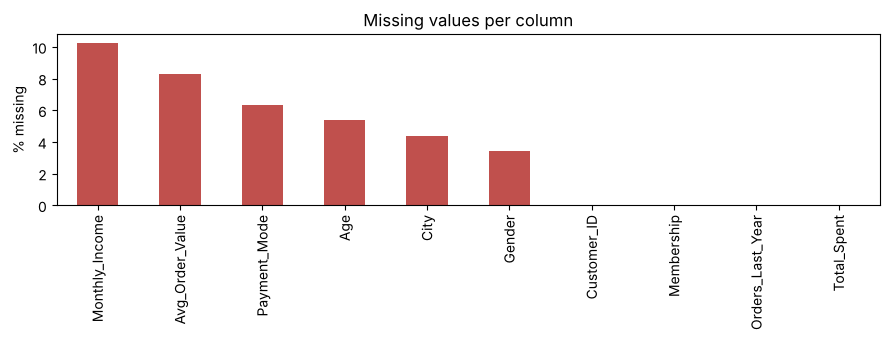

In [9]:
plt.figure(figsize=(9, 3.5))
(df.isnull().mean() * 100).sort_values(ascending=False).plot(kind="bar", color="#c0504d")
plt.ylabel("% missing"); plt.title("Missing values per column"); plt.tight_layout(); plt.show()

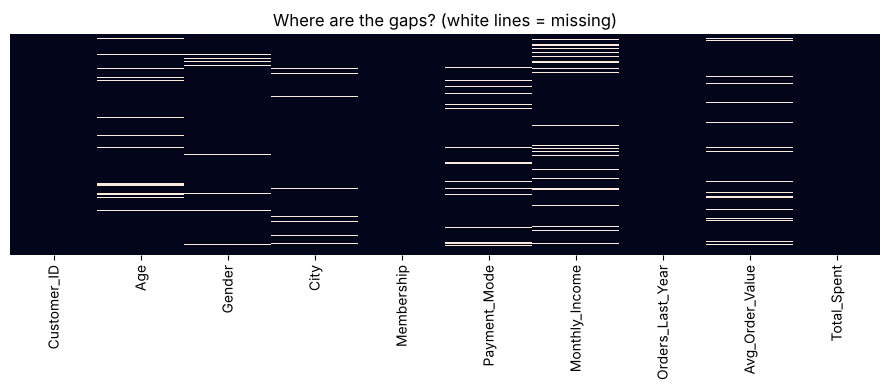

In [10]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Where are the gaps? (white lines = missing)"); plt.tight_layout(); plt.show()

### Is the missing data random?
A good explorer checks *who* is missing. Here **Monthly_Income is missing more for Basic members**.

In [11]:
print((df.groupby("Membership")["Monthly_Income"].apply(lambda s: round(s.isnull().mean() * 100, 1))).sort_values())

Membership
GOLD         0.0
PLATINUM     0.0
basic        0.0
SILVER       0.0
silver       0.0
Silver       3.9
Gold         4.7
Platinum     4.8
Basic       15.7
Name: Monthly_Income, dtype: float64


In [12]:
df["Membership_clean"] = df["Membership"].str.strip().str.title()
print((df.groupby("Membership_clean")["Monthly_Income"].apply(lambda s: round(s.isnull().mean() * 100, 1))))
df = df.drop(columns="Membership_clean")

Membership_clean
Basic       15.7
Gold         4.6
Platinum     4.8
Silver       3.8
Name: Monthly_Income, dtype: float64


### How many gaps does a row have?

In [13]:
gaps = df.isnull().sum(axis=1)
print(gaps.value_counts().sort_index())
print("Rows with 3 or more gaps:", (gaps >= 3).sum())

0    1020
1     397
2      75
3       8
Name: count, dtype: int64
Rows with 3 or more gaps: 8


**Key point:** `dropna()` on the whole table would remove many rows. Show the cost:

In [14]:
print("Rows now:", len(df), "| after dropna():", len(df.dropna()))

Rows now: 1500 | after dropna(): 1020


## 5 · Duplicates  *(today)*

In [15]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique Customer_IDs:", df["Customer_ID"].nunique(), "of", len(df))
print()
print(df[df.duplicated(keep=False)].sort_values("Customer_ID").head(6))

Exact duplicate rows: 35
Unique Customer_IDs: 1465 of 1500

     Customer_ID   Age  Gender        City Membership Payment_Mode  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
778        C0062  39.0    Male       Kochi     Silver   Debit Card         53100.0              17.0            256.0       4646.0
1205       C0062  39.0    Male       Kochi     Silver   Debit Card         53100.0              17.0            256.0       4646.0
1174       C0070  30.0    Male   Kozhikode     Silver          NaN         59200.0               6.0            363.0       2043.0
555        C0070  30.0    Male   Kozhikode     Silver          NaN         59200.0               6.0            363.0       2043.0
906        C0071  31.0  Female  Trivandrum      Basic   Debit Card         25600.0               7.0            349.0       2242.0
800        C0071  31.0  Female  Trivandrum      Basic   Debit Card         25600.0               7.0            349.0       2242.0


In [16]:
ids = df["Customer_ID"].value_counts()
print("IDs appearing more than once:", (ids > 1).sum())
print("Are all repeated IDs exact copies?", df.duplicated().sum() == (len(df) - df["Customer_ID"].nunique()))

IDs appearing more than once: 35
Are all repeated IDs exact copies? True


**Key point:** here every repeated ID is an **exact copy**, so they are true duplicates and safe to delete. (In the clinic dataset repeat IDs were real repeat visits; always *check*, do not assume.)

## 6 · Wrong values  *(data thinking)*

In [17]:
print(df["Age"].describe().round(1))
print("Impossible ages:", sorted(df[(df["Age"] < 18) | (df["Age"] > 100)]["Age"].tolist()))

count    1419.0
mean       34.2
std        10.6
min        -3.0
25%        27.0
50%        34.0
75%        41.0
max       150.0
Name: Age, dtype: float64
Impossible ages: [-3.0, 0.0, 112.0, 150.0]


In [18]:
print(df[(df["Age"] < 18) | (df["Age"] > 100)])

     Customer_ID    Age  Gender        City Membership      Payment_Mode  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
469        C1435  112.0  Female       Kochi      Basic  Cash on Delivery         40600.0              10.0            357.0       3876.0
556        C0169   -3.0  Female      Kollam   Platinum       Credit Card         64500.0              21.0            394.0       8300.0
583        C1393    0.0    Male       Kochi      Basic               NaN         24300.0               7.0            814.0       5787.0
1201       C1246  150.0    Male  Trivandrum       Gold               UPI             NaN              16.0            363.0       6368.0


The shop only serves adults (18+), so `0`, `-3`, `112` and `150` are **entry mistakes**, not real ages. They are not blank, so `isnull()` will not show them.

## 7 · Plots  *(Matplotlib / Seaborn classes)*

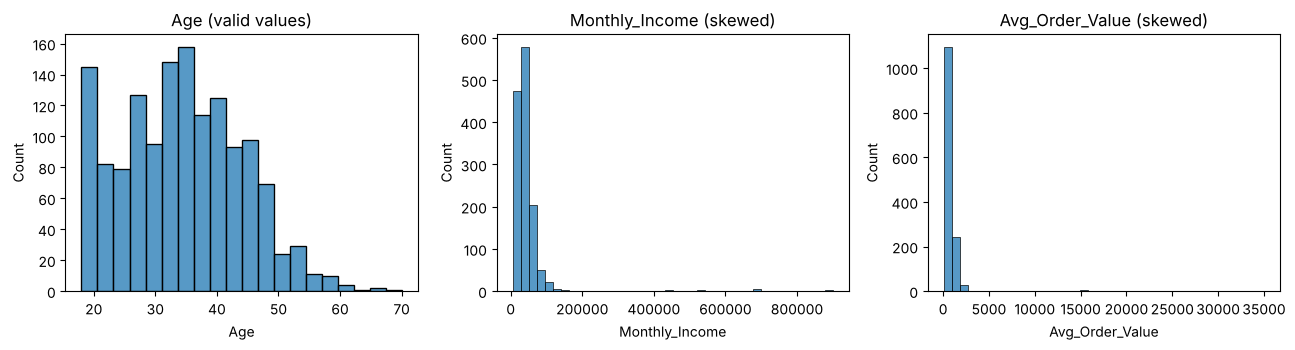

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
sns.histplot(df["Age"].where(df["Age"].between(18, 70)), ax=ax[0], bins=20); ax[0].set_title("Age (valid values)")
sns.histplot(df["Monthly_Income"], ax=ax[1], bins=40); ax[1].set_title("Monthly_Income (skewed)")
sns.histplot(df["Avg_Order_Value"], ax=ax[2], bins=40); ax[2].set_title("Avg_Order_Value (skewed)")
plt.tight_layout(); plt.show()

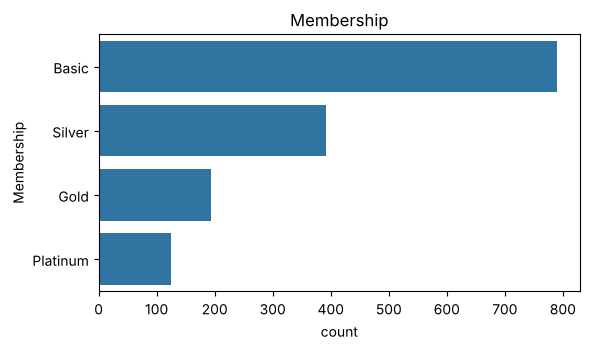

In [20]:
plt.figure(figsize=(6, 3.6))
sns.countplot(y=df["Membership"].str.title(), order=["Basic", "Silver", "Gold", "Platinum"])
plt.title("Membership")
plt.tight_layout(); plt.show()

The histogram of `Monthly_Income` is very stretched to the right: a few very high values. We will look at them with box plots in the Session 44 section.

## 8 · Relations  *(groupby, pivot, correlation)*

In [21]:
df["Membership"] = df["Membership"].str.strip().str.title()
print(df.groupby("Membership")[["Monthly_Income", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent"]].median().round(0).loc[["Basic", "Silver", "Gold", "Platinum"]])

            Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
Membership                                                                
Basic              29500.0               6.0            540.0       2966.0
Silver             33600.0               7.0            618.0       4107.0
Gold               40600.0               9.0            619.0       5650.0
Platinum           50000.0              10.0            713.0       7839.0


In [22]:
print(df[["Age", "Monthly_Income", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent"]].corr().round(2))

                   Age  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
Age               1.00           -0.04              0.01             0.02        -0.03
Monthly_Income   -0.04            1.00              0.01             0.01         0.08
Orders_Last_Year  0.01            0.01              1.00            -0.01         0.25
Avg_Order_Value   0.02            0.01             -0.01             1.00         0.13
Total_Spent      -0.03            0.08              0.25             0.13         1.00


### A smart find: Avg_Order_Value can be calculated
`Total_Spent` and `Orders_Last_Year` have no gaps, and Total_Spent is about Orders × Avg_Order_Value. So a missing Avg_Order_Value can be **derived**, which is better than guessing with a mean.

In [23]:
check = df.dropna(subset=["Avg_Order_Value"])
est = (check["Total_Spent"] / check["Orders_Last_Year"])
print("Median % difference between Total/Orders and Avg_Order_Value:", round(((est - check["Avg_Order_Value"]).abs() / check["Avg_Order_Value"] * 100).median(), 1))

Median % difference between Total/Orders and Avg_Order_Value: 4.9


## 9 · Cleaning decisions  *(today)*  with the reason for each

In [24]:
print("Start:", df.shape)

# 1. Exact duplicates are the same customer entered twice -> drop
df = df.drop_duplicates().reset_index(drop=True)
print("After duplicates:", df.shape)

# 2. Same thing written differently -> make one spelling
df["City"] = df["City"].str.strip().str.title()
df["Gender"] = df["Gender"].replace({"M": "Male", "F": "Female"})
print(df["City"].value_counts().to_dict())
print(df["Gender"].value_counts(dropna=False).to_dict())

Start: (1500, 10)
After duplicates: (1465, 10)
{'Kochi': 357, 'Trivandrum': 227, 'Kozhikode': 206, 'Thrissur': 173, 'Kollam': 141, 'Kannur': 113, 'Alappuzha': 112, 'Palakkad': 71}
{'Female': 722, 'Male': 657, nan: 50, 'Other': 36}


**Decision table (model)**
| Problem | Action | Why |
|---|---|---|
| 35 exact duplicate rows | Dropped | Same customer entered twice; we checked that repeated IDs are exact copies |
| `M`/`F` in Gender, spelling variants in City and Membership | Standardised | The same thing must have one spelling |
| Blanks in 6 columns | **Not handled in this session** | Filling missing values comes in the next class (see the Session 44 section) |
| Impossible ages (0, -3, 112, 150) | **Not handled in this session** | Treated together with the missing values in the Session 44 section |
| Extreme income, orders, order value | **Not handled in this session** | Looked at with box plots in the Session 44 section |

## 10 · Before and after

In [25]:
print("Rows   :", len(raw), "->", len(df))
print("Duplicate rows:", raw.duplicated().sum(), "->", df.duplicated().sum())
print("Missing values (still to handle):", int(df.isnull().sum().sum()))

Rows   : 1500 -> 1465
Duplicate rows: 35 -> 0
Missing values (still to handle): 560


---
## What was hidden in the data (answer sheet)
* 1500 rows, 10 columns. **35 exact duplicates** (1465 unique Customer_IDs).
* Missing: Age 81, Gender 51, City 66, Payment_Mode 95, Monthly_Income 154, Avg_Order_Value 124. Customer_ID, Membership, Orders_Last_Year and Total_Spent are complete.
* Missing Monthly_Income is **linked to Basic members** (about 16% vs 4 to 5% for other memberships), so it is not random.
* Wrong values: 4 impossible ages (0, -3, 112, 150); Gender written as `M`/`F`; City and Membership spelling variants.
* Extreme values: incomes 4.5 to 9 lakh, orders up to 310, order values 15,000 to 35,000 (Session 44 section).
* Avg_Order_Value can be derived from Total_Spent / Orders (used in the Session 44 section).

## Check your own work
| Level | What you did |
|---|---|
| Basic | `shape`, `head`, `isnull().sum()`, `duplicated().sum()`, `drop_duplicates()` |
| Good | missing %, `value_counts` and spotting spelling variants, `describe()`, checked whether repeated IDs are exact copies |
| Excellent | missing by group (Basic members), impossible ages found, plots, a written reason for each action |

## Common mistakes
* `dropna()` on the whole table (1500 rows become 1020, see Section 4).
* Treating `kochi` and `Kochi` as different cities.
* Deleting duplicates without checking that they are exact copies.
* Believing `isnull()` finds all bad data (ages 0 and 150 are not blank).
* Not saving the result of `drop_duplicates()` back to `df`.

## Think about it
1. Why are some duplicates safe to delete and others not?
2. Why is `dropna()` on the whole table costly here?
3. Which column has missing values linked to another column, and what does it mean?
4. Which values are wrong even though they are not blank?

<div style="background:#1a5fb4;color:#ffffff;padding:18px 22px;border-radius:8px;margin-top:30px">
<div style="font-size:13px;letter-spacing:1px">NEW SECTION · SESSION 44 · CONTINUATION OF THIS NOTEBOOK</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Outliers</div>
<div style="font-size:14px;margin-top:6px">Use-Case Discussion solution · everything above this banner is the Session 42 solution (Missing Values &amp; Duplicates)</div>
</div>

# Outliers
**ICT Academy of Kerala · Session 44 · Use-Case Discussion: Outliers · Solution (shared after submission)**

This section contains **only what was taught** up to the Session 43 class: handling missing values and drawing box plots. The code follows the style of the class notebook (`select_dtypes`, loops over columns, subplots). The IQR / Z-score code and **handling** the outliers were not taught yet, so they are not here; they will come in the next session's solution.

**Continue in this same notebook.** `df` is the data after the Session 42 section (duplicates removed, spelling standardised).

| Part | What it contains | Class it comes from |
|---|---|---|
| A | Handling the missing values (carried over from Session 42) | Session 43 class |
| B | Exploring the outliers with box plots (no handling yet) | Session 43 class + descriptive statistics |

<div style="background:#b26a00;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:18px;font-size:20px;font-weight:bold">Part A · Handling missing values (carried over from the Session 42 use-case)</div>

## Outliers · A1 · Separate numerical and categorical columns
Same as in class: `select_dtypes`.

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)

# numerical columns
num_cols = df.select_dtypes(include=["number"]).columns
# categorical columns (everything that is not a number)
cat_cols = df.select_dtypes(exclude=["number"]).columns
print(list(num_cols))
print(list(cat_cols))
print(df.isna().sum())

['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value', 'Total_Spent']
['Customer_ID', 'Gender', 'City', 'Membership', 'Payment_Mode']
Customer_ID           0
Age                  78
Gender               50
City                 65
Membership            0
Payment_Mode         93
Monthly_Income      151
Orders_Last_Year      0
Avg_Order_Value     123
Total_Spent           0
dtype: int64


## Outliers · A2 · Plot a histogram of every numerical column
The shape tells us whether to fill with the **mean** or the **median**.

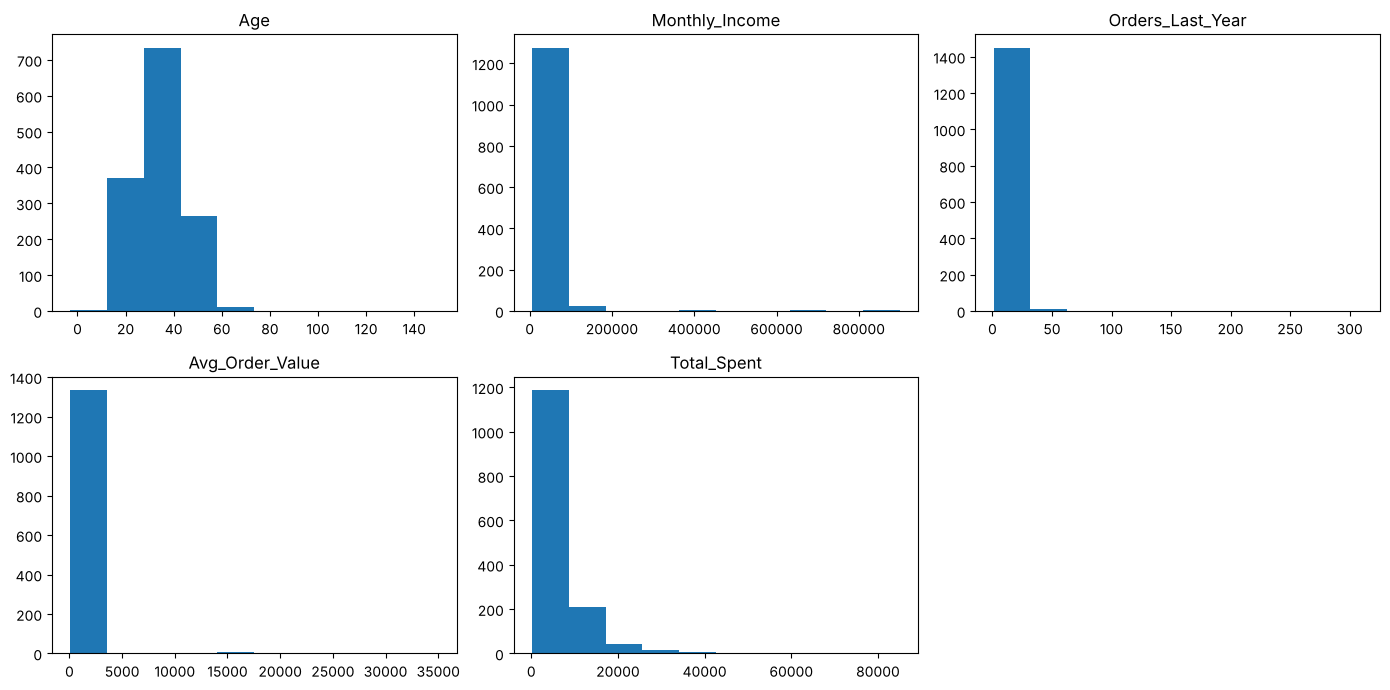

In [27]:
plt.figure(figsize=(14, 7))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    plt.hist(df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

**What to notice:** `Age` is balanced, but `Monthly_Income`, `Orders_Last_Year`, `Avg_Order_Value` and `Total_Spent` are stretched to the right (a few very high values). For skewed columns the **median** is the safer choice, because extreme values pull the mean up.

## Outliers · A3 · Impossible ages
Ages 0, -3, 112 and 150 are not blanks but cannot be true (the shop serves adults only). We turn them into missing values first, so they are filled together with the real blanks.

In [28]:
bad_age = (df["Age"] < 18) | (df["Age"] > 100)
print("Impossible ages:", sorted(df[bad_age]["Age"].tolist()))
df.loc[bad_age, "Age"] = np.nan
print("Missing ages now:", df["Age"].isna().sum())

Impossible ages: [-3.0, 0.0, 112.0, 150.0]
Missing ages now: 82


## Outliers · A4 · Fill the missing values
Numerical columns with the **median** (as in class), one column at a time:

In [29]:
# numerical columns: replace the missing values with the median
for col in ["Age", "Monthly_Income"]:
    df[col] = df[col].fillna(df[col].median())

print(df[["Age", "Monthly_Income"]].isna().sum())

Age               0
Monthly_Income    0
dtype: int64


> **Note:** in class we also used `fillna(..., inplace=True)` on a single column. In newer pandas this gives a *FutureWarning* ("chained assignment") and will stop working, so here we **assign the result back**: `df[col] = df[col].fillna(...)`. The result is the same.

Categorical columns: `Payment_Mode` has one clear favourite, so use the **mode**. For `Gender` and `City` we do not guess; we write `Unknown`.

In [30]:
df["Payment_Mode"] = df["Payment_Mode"].fillna(df["Payment_Mode"].mode()[0])
df["Gender"] = df["Gender"].fillna("Unknown")
df["City"] = df["City"].fillna("Unknown")

print(df[["Payment_Mode", "Gender", "City"]].isna().sum())

Payment_Mode    0
Gender          0
City            0
dtype: int64


`Avg_Order_Value` is special. `Total_Spent` and `Orders_Last_Year` have no gaps and `Total_Spent` is about Orders × Avg_Order_Value, so we can **calculate** the missing value instead of guessing it with the median:

In [31]:
df["Avg_Order_Value"] = df["Avg_Order_Value"].fillna((df["Total_Spent"] / df["Orders_Last_Year"]).round())

print(df.isna().sum())

Customer_ID         0
Age                 0
Gender              0
City                0
Membership          0
Payment_Mode        0
Monthly_Income      0
Orders_Last_Year    0
Avg_Order_Value     0
Total_Spent         0
dtype: int64


**Decision table (model)**
| Column | Action | Why |
|---|---|---|
| Age | Impossible values to missing, then median | Wrong values are not data; median is safe |
| Monthly_Income | Median | Skewed column, extreme values pull the mean |
| Payment_Mode | Mode (UPI) | One clearly most common value |
| Gender, City | `Unknown` | A category should not be guessed |
| Avg_Order_Value | Calculated as Total_Spent / Orders | The information already exists in other columns |

*Optional improvement:* Monthly_Income is missing more for Basic members, so a median **per membership** (`groupby("Membership")` and `transform("median")`) would be fairer than one overall median.

## Outliers · A5 · Before and after

In [32]:
print("Rows   :", len(raw), "->", len(df))
print("Missing:", int(raw.isnull().sum().sum()), "->", int(df.isnull().sum().sum()))
compare = pd.DataFrame({"before": raw[["Age", "Monthly_Income", "Avg_Order_Value"]].mean(), "after": df[["Age", "Monthly_Income", "Avg_Order_Value"]].mean()})
print(compare.round(1))

Rows   : 1500 -> 1465
Missing: 571 -> 0
                  before    after
Age                 34.2     34.2
Monthly_Income   43418.4  42408.1
Avg_Order_Value    817.3    800.5


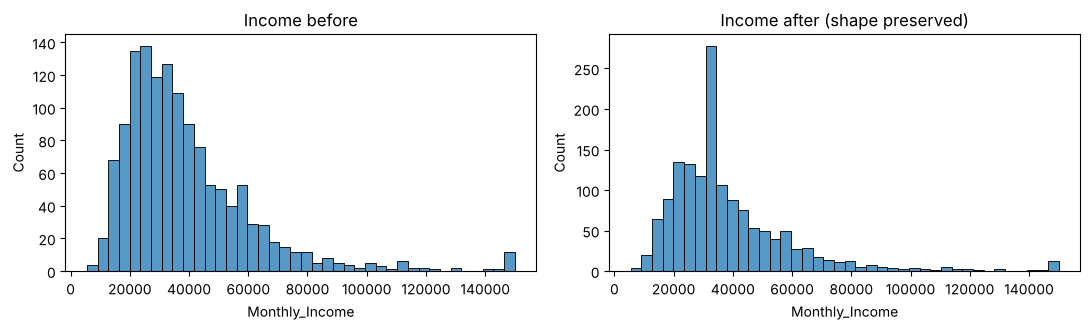

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
sns.histplot(raw["Monthly_Income"].dropna().clip(upper=150000), ax=ax[0], bins=40); ax[0].set_title("Income before")
sns.histplot(df["Monthly_Income"].clip(upper=150000), ax=ax[1], bins=40); ax[1].set_title("Income after (shape preserved)")
plt.tight_layout(); plt.show()

**What to notice:** the missing values are gone (571 to 0), the duplicates are gone (1500 to 1465 rows), and the **shape of the income histogram is the same** after filling. The tall bar in the middle is the median that filled the blanks, so the filling did not distort the data.

<div style="background:#2e7d32;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:26px;font-size:20px;font-weight:bold">Part B · Exploring the outliers with box plots (no handling yet)</div>

## Outliers · B1 · Which columns can have outliers?
Outliers are found in **numbers**, not in text columns. We skip `Age` for the moment (it is normal after cleaning).

In [34]:
before = df.copy()          # keep a copy of the cleaned data
print(df[num_cols].dtypes)
print()
print(df[num_cols].describe().round(1))

Age                 float64
Monthly_Income      float64
Orders_Last_Year    float64
Avg_Order_Value     float64
Total_Spent         float64
dtype: object

          Age  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
count  1465.0          1465.0            1465.0           1465.0       1465.0
mean     34.2         42408.1               9.0            800.5       5720.8
std       9.5         60320.6              15.7           1664.2       6537.9
min      18.0          5500.0               1.0             81.0        157.0
25%      27.0         25100.0               4.0            401.0       1936.0
50%      34.0         33600.0               7.0            587.0       3813.0
75%      41.0         44800.0              11.0            877.0       7227.0
max      70.0        900000.0             310.0          35000.0      85073.0


In [35]:
gap = pd.DataFrame({"mean": df[num_cols].mean(), "median": df[num_cols].median(), "75%": df[num_cols].quantile(0.75), "max": df[num_cols].max()})
gap["max / 75%"] = (gap["max"] / gap["75%"]).round(1)
print(gap.round(1))

                     mean   median      75%       max  max / 75%
Age                  34.2     34.0     41.0      70.0        1.7
Monthly_Income    42408.1  33600.0  44800.0  900000.0       20.1
Orders_Last_Year      9.0      7.0     11.0     310.0       28.2
Avg_Order_Value     800.5    587.0    877.0   35000.0       39.9
Total_Spent        5720.8   3813.0   7227.0   85073.0       11.8


**What to notice:** for `Monthly_Income`, `Orders_Last_Year` and `Avg_Order_Value` the **maximum is many times larger than the 75% value**, and the mean is above the median. A few values are far away from everyone else.

## Outliers · B2 · Box plots
One box plot for each column, all in one picture (the class method).

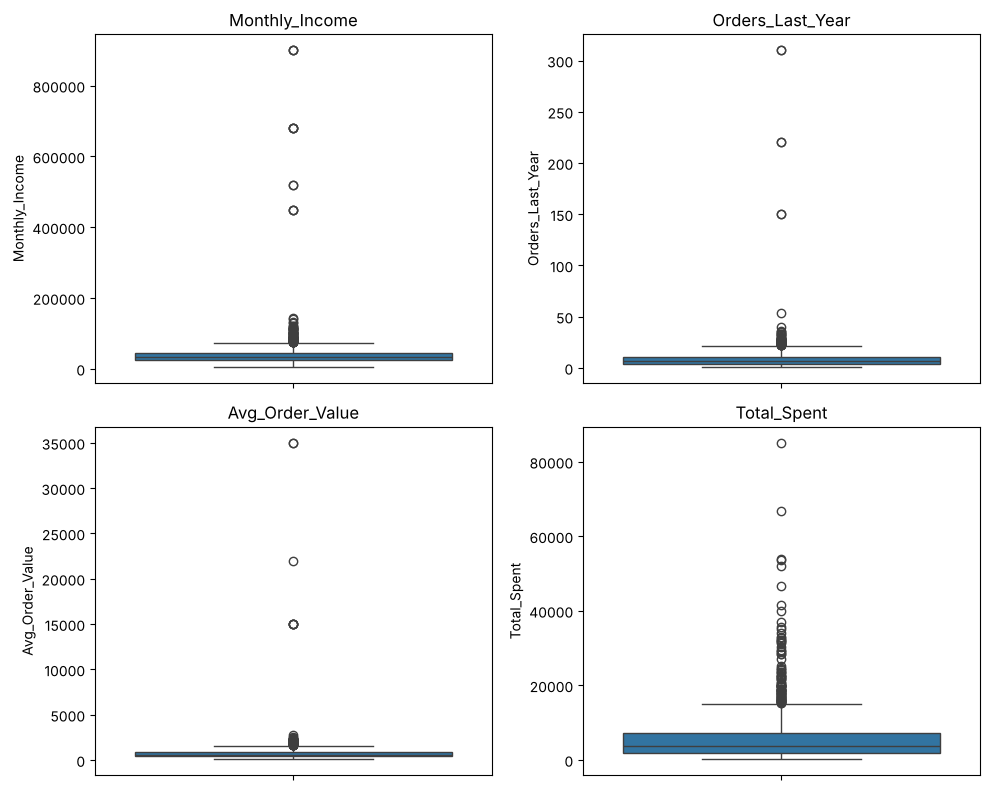

In [36]:
plot_cols = ["Monthly_Income", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent"]

plt.figure(figsize=(10, 8))
for i, col in enumerate(plot_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

**What to notice:** the dots above the whiskers are the unusual values (the outliers the plot shows). `Total_Spent` has many dots, but they form a smooth tail (real big spenders). The other three have a few dots **far** away from the rest.

## Outliers · B3 · Histogram and scatter plot

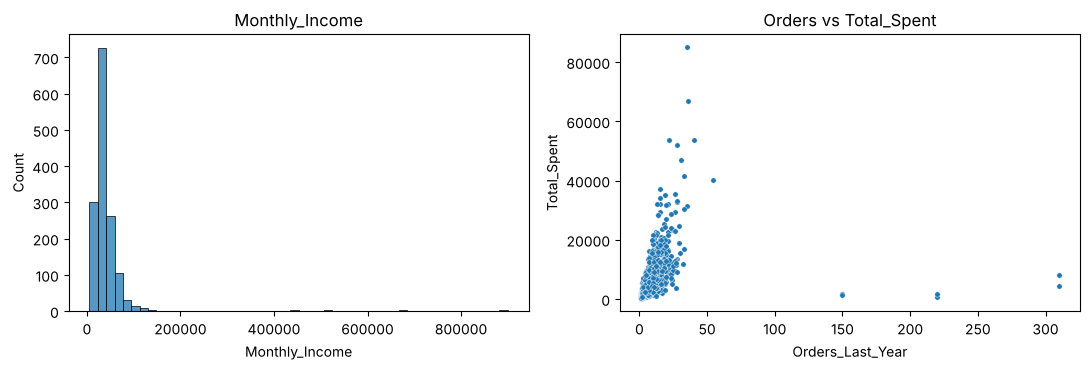

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["Monthly_Income"], bins=50, ax=ax[0]); ax[0].set_title("Monthly_Income")
sns.scatterplot(x="Orders_Last_Year", y="Total_Spent", data=df, ax=ax[1], s=15); ax[1].set_title("Orders vs Total_Spent")
plt.tight_layout(); plt.show()

**What to notice:** in the histogram almost everyone is below ₹1 lakh, and a few incomes sit far to the right (₹4.5 to ₹9 lakh). In the scatter plot most customers lie along a pattern (more orders, more spent), but a few points with **very high orders (150 to 310) sit at low Total_Spent**. That is strange and worth investigating.

## Outliers · B4 · Look at the actual extreme rows

In [38]:
print(df.sort_values("Monthly_Income", ascending=False).head(8)[["Customer_ID", "Membership", "Monthly_Income", "Total_Spent"]])

     Customer_ID Membership  Monthly_Income  Total_Spent
1375       C0929      Basic        900000.0       2220.0
1104       C0168   Platinum        900000.0      14148.0
209        C0573   Platinum        900000.0      32218.0
541        C1339      Basic        680000.0       1085.0
1311       C0299     Silver        680000.0       3216.0
33         C0395      Basic        680000.0        973.0
1458       C1150   Platinum        680000.0       5419.0
780        C0331      Basic        520000.0        458.0


In [39]:
print(df.sort_values("Orders_Last_Year", ascending=False).head(8)[["Customer_ID", "Membership", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent"]])

     Customer_ID Membership  Orders_Last_Year  Avg_Order_Value  Total_Spent
387        C0835      Basic             310.0            749.0       8259.0
1401       C1133     Silver             310.0           1168.0       4364.0
570        C0399      Basic             220.0            264.0        807.0
753        C1206       Gold             220.0            574.0       1577.0
118        C0619      Basic             150.0            564.0       1565.0
484        C0092      Basic             150.0            350.0       1468.0
487        C1448   Platinum              54.0            691.0      40027.0
1348       C0886   Platinum              40.0           1284.0      53834.0


In [40]:
print(df.sort_values("Avg_Order_Value", ascending=False).head(10)[["Customer_ID", "Membership", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent"]])

     Customer_ID Membership  Orders_Last_Year  Avg_Order_Value  Total_Spent
1346       C0244      Basic               4.0          35000.0       1113.0
225        C0890   Platinum               3.0          35000.0       1884.0
69         C1112      Basic              10.0          22000.0       8537.0
1051       C0362   Platinum               5.0          15000.0       3471.0
818        C1367       Gold              21.0          15000.0      13115.0
316        C1236     Silver              11.0          15000.0      16897.0
414        C0120      Basic               2.0          15000.0       1019.0
1310       C0842      Basic               5.0          15000.0       3796.0
209        C0573   Platinum              13.0           2717.0      32218.0
1054       C1266     Silver               2.0           2529.0       5404.0


**What to notice:** a few rows are *far* beyond everyone else (income above ₹4 lakh, 150 to 310 orders, an average order of ₹15,000 to ₹35,000). Then there is a gap, and the rest of the list looks ordinary.

## Outliers · B5 · Real value or mistake?
`Total_Spent` should be about **Orders × Avg_Order_Value**. If it is not, one of the numbers is wrong. Let us check every row.

In [41]:
df["check"] = df["Orders_Last_Year"] * df["Avg_Order_Value"] / df["Total_Spent"]
bad = df[(df["check"] < 0.8) | (df["check"] > 1.25)]
print("Rows where Orders x Order Value does not match Total_Spent:", len(bad))
print(bad.sort_values("check")[["Customer_ID", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent", "check"]].round(1))
df = df.drop(columns="check")

Rows where Orders x Order Value does not match Total_Spent: 14
     Customer_ID  Orders_Last_Year  Avg_Order_Value  Total_Spent  check
316        C1236              11.0          15000.0      16897.0    9.8
1310       C0842               5.0          15000.0       3796.0   19.8
1051       C0362               5.0          15000.0       3471.0   21.6
818        C1367              21.0          15000.0      13115.0   24.0
69         C1112              10.0          22000.0       8537.0   25.8
387        C0835             310.0            749.0       8259.0   28.1
414        C0120               2.0          15000.0       1019.0   29.4
484        C0092             150.0            350.0       1468.0   35.8
118        C0619             150.0            564.0       1565.0   54.1
225        C0890               3.0          35000.0       1884.0   55.7
570        C0399             220.0            264.0        807.0   72.0
753        C1206             220.0            574.0       1577.0   80.1
1

**What to notice:** nearly every row matches, and 14 rows do not. In each of those **either Orders or Avg_Order_Value is a mistake**: `310 orders` with a Total_Spent of ₹5,000 cannot be true. These extremes are **errors (probably typing mistakes)**, not unusual customers.

For `Monthly_Income` there is **no other column to check against**. A ₹9 lakh income on a Basic member who spent only ₹2,220 looks suspicious, but it is not impossible, so we cannot call it an error.

## Outliers · B6 · What we noticed (no handling yet)
| Column | What we saw | Looks like |
|---|---|---|
| Orders_Last_Year | 6 values of 150 to 310 that do not match Total_Spent | **Mistake** (typing error) |
| Avg_Order_Value | 8 values of ₹15,000 to ₹35,000 that do not match Total_Spent | **Mistake** (typing error) |
| Monthly_Income | about 12 values of ₹4.5 lakh to ₹9 lakh, cannot be verified | **Rare but possible**, needs a decision |
| Total_Spent | high values, but consistent with Orders x Order Value | **Real** big spenders |
| Age | normal after cleaning | No outlier |

**What to do with each group** (remove? correct? keep? cap?) will be decided with the outlier-handling methods in the next session's solution.

---
## Outliers · What was hidden in the data (answer sheet)
* **6** impossible order counts (150, 220, 310), **8** huge order values (₹15,000 to ₹35,000) and **12** extreme incomes (₹4.5 lakh to ₹9 lakh).
* The order counts and order values are **mistakes**: they do not match `Total_Spent`. The cross-check in B5 finds them.
* The incomes cannot be cross-checked, so they are rare-but-possible.

## Outliers · Check your own work
| Level | What you did |
|---|---|
| Basic | filled the missing values column by column; drew box plots for the number columns |
| Good | chose median for skewed columns and mode for text; looked at the extreme rows with `sort_values`; explained which look like mistakes |
| Excellent | calculated Avg_Order_Value instead of guessing; cross-checked Orders × Order Value against Total_Spent; separated mistakes from rare-but-real values, with a reason for each |

## Outliers · Common mistakes
* Filling skewed columns with the **mean** (extreme values pull it up).
* `fillna` result not saved back to `df`.
* Filling a column with the median and then using it to cross-check (it breaks the Orders × Order Value check; that is why Avg_Order_Value is calculated).
* Calling every box-plot dot an error (some are real, rare customers).

## Outliers · Think about it
1. Why is the median safer than the mean for Monthly_Income?
2. Why can an outlier be real?
3. How did another column help us decide which values were mistakes?

<div style="background:#1a5fb4;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:20px">End of the Session 44 · Outliers section</div>

<div style="background:#6a1b9a;color:#ffffff;padding:18px 22px;border-radius:8px;margin-top:40px">
<div style="font-size:13px;letter-spacing:1px">NEW SECTION · SESSION 46 · CONTINUATION OF THIS NOTEBOOK</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Encoding</div>
<div style="font-size:14px;margin-top:6px">Use-Case Discussion solution · everything above this banner is the Session 42 (Missing Values &amp; Duplicates) and Session 44 (Outliers) solution</div>
</div>

# Encoding
**ICT Academy of Kerala · Session 46 · Use-Case Discussion: Encoding · Solution (shared after submission)**

**How to use this section:** compare it with your own work. It shows **one good way** to explore and encode the QuickKart data. Your steps may differ. What matters is that every decision has a **reason**.

**Continue in this same notebook.** `df` is the cleaned data from the sections above. We do not repeat the earlier solutions.

**Scenario:** the data science team wants to train a model on the QuickKart customers, but a model can only use **numbers**. Which columns are text, how should each one become numbers, and why?

| Part | What it contains | Class it comes from |
|---|---|---|
| A | Handling the outliers (carried over from the Session 44 use-case) | Outliers class |
| B | Exploring the text columns and encoding them | Encoding class |

**Map of exploration to classes (Part B)**
| Section | What is explored | Class it comes from |
|---|---|---|
| B1 | which columns are text, how many values each has | pandas basics |
| B2 | is the text clean enough to encode? | **Session 42 and 44 work** |
| B3 | Label encoding and why it can mislead | **today** |
| B4 | Ordinal encoding for Membership | **today** |
| B5 | One-hot encoding for Payment_Mode and Gender | **today** |
| B6 | City: many values, other options | **today** |
| B7 | Customer_ID: a column we do not encode | data thinking |
| B8 | Building the final numeric table | **today** |
| B9 | checking the result | pandas |
| B10 | decisions with reasons | **today** |

<div style="background:#b26a00;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:18px;font-size:20px;font-weight:bold">Part A · Handling the outliers (carried over from the Session 44 use-case)</div>

## Encoding · A1 · IQR method
A value is an outlier if it is below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**.

In [42]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in num_cols:
    low, high = iqr_bounds(df[col])
    n = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, round(low, 1), round(high, 1), n, round(n / len(df) * 100, 1)])
print(pd.DataFrame(rows, columns=["column", "lower", "upper", "outliers", "%"]).to_string(index=False))

          column   lower   upper  outliers   %
             Age     6.0    62.0         4 0.3
  Monthly_Income -4450.0 74350.0        81 5.5
Orders_Last_Year    -6.5    21.5        57 3.9
 Avg_Order_Value  -313.0  1591.0        69 4.7
     Total_Spent -6000.5 15163.5        88 6.0


**What to notice:** IQR flags **many** rows in the skewed columns, far more than the handful of extreme values. In a right-skewed column a long, natural tail of high spenders is normal. So **IQR says "unusual", not "wrong"**.

In [43]:
df["Mem"] = pd.Categorical(df["Membership"], ["Basic", "Silver", "Gold", "Platinum"], ordered=True)
hi = df["Monthly_Income"] > iqr_bounds(df["Monthly_Income"])[1]
print("Share of IQR-high incomes by membership (%):")
print((hi.groupby(df["Mem"], observed=True).mean() * 100).round(1))
df = df.drop(columns="Mem")

Share of IQR-high incomes by membership (%):
Mem
Basic        2.3
Silver       5.2
Gold        10.5
Platinum    19.0
Name: Monthly_Income, dtype: float64


Higher memberships have more high incomes, which fits real life: **a long upper tail is natural in income**, so not every IQR-flagged income should be treated as a problem.

## Encoding · A2 · Z-score method
A value is an outlier if it is more than **3 standard deviations** from the mean.

In [44]:
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
compare_out = pd.DataFrame({"IQR": [((df[c] < iqr_bounds(df[c])[0]) | (df[c] > iqr_bounds(df[c])[1])).sum() for c in num_cols],
                            "Z-score": (z.abs() > 3).sum().values}, index=num_cols)
print(compare_out)

                  IQR  Z-score
Age                 4        4
Monthly_Income     81       12
Orders_Last_Year   57        6
Avg_Order_Value    69        8
Total_Spent        88       26


**What to notice:** Z-score flags **fewer** rows than IQR, mainly the really extreme ones. But the mean and standard deviation are themselves pulled by the extreme values, so Z-score can hide outliers when there are several. Neither method knows what is *true*.

## Encoding · A3 · Treatment options compared
For `Monthly_Income` (cannot be verified) compare the choices:

In [45]:
inc = df["Monthly_Income"]
low, high = iqr_bounds(inc)
p99 = inc.quantile(0.99)
options = {
    "keep as it is": inc,
    "remove IQR outliers": inc[(inc >= low) & (inc <= high)],
    "cap at IQR upper bound": inc.clip(upper=high),
    "cap at 99th percentile": inc.clip(upper=p99),
    "log transform": np.log1p(inc),
}
t = pd.DataFrame({k: {"rows": len(v), "mean": v.mean(), "median": v.median(), "std": v.std(), "skew": v.skew()} for k, v in options.items()}).T
print(t.round(2))

                          rows      mean    median       std   skew
keep as it is           1465.0  42408.12  33600.00  60320.60  10.47
remove IQR outliers     1384.0  34596.60  33600.00  13617.93   0.68
cap at IQR upper bound  1465.0  36794.57  33600.00  16055.83   0.82
cap at 99th percentile  1465.0  38126.23  33600.00  20255.66   1.94
log transform           1465.0     10.45     10.42      0.53   1.34


**What to notice:**
* **Remove IQR outliers** loses many real customers (see `rows`) just to fix a few. Too costly.
* **Cap at IQR bound** squashes all high earners to one value and changes the shape of the data.
* **Cap at the 99th percentile** only touches the most extreme 1% and keeps the shape.
* **Log transform** reduces skew but changes the unit; this belongs to the scaling and transformation session.
* **Keep** is safe only if the model or report is not sensitive to extremes.

## Encoding · A4 · Decisions with reasons, and before vs after

In [46]:
# a) Orders: extreme count that contradicts Total_Spent -> error, recalculate from Total_Spent / Avg_Order_Value
fix_orders = df["Orders_Last_Year"] > 100
print("Orders corrected:", fix_orders.sum())
df.loc[fix_orders, "Orders_Last_Year"] = (df.loc[fix_orders, "Total_Spent"] / df.loc[fix_orders, "Avg_Order_Value"]).round().clip(lower=1)

# b) Avg_Order_Value: extreme value that contradicts Total_Spent -> error, recalculate from Total_Spent / Orders
fix_aov = df["Avg_Order_Value"] > 10000
print("Order values corrected:", fix_aov.sum())
df.loc[fix_aov, "Avg_Order_Value"] = (df.loc[fix_aov, "Total_Spent"] / df.loc[fix_aov, "Orders_Last_Year"]).round()

# c) Monthly_Income: cannot be verified, real customers may earn a lot -> cap at the 99th percentile
cap = df["Monthly_Income"].quantile(0.99)
print("Income cap (99th percentile):", round(cap), "| incomes capped:", (df["Monthly_Income"] > cap).sum())
df["Monthly_Income"] = df["Monthly_Income"].clip(upper=cap)

Orders corrected: 6
Order values corrected: 8
Income cap (99th percentile): 130248 | incomes capped: 15


**Decision table (model)**
| Column | Problem | Action | Why |
|---|---|---|---|
| Orders_Last_Year | 6 values of 150 to 310 that do not match Total_Spent | Recalculated as Total_Spent / Avg_Order_Value | A wrong typed value; the information exists in other columns |
| Avg_Order_Value | 8 values of ₹15,000 to ₹35,000 that do not match Total_Spent | Recalculated as Total_Spent / Orders | Same reason |
| Monthly_Income | about 12 values of ₹4.5 lakh to ₹9 lakh, cannot be verified | Capped at the 99th percentile | Probably real but rare; capping keeps the customer and limits the influence |
| Monthly_Income (IQR-high, but natural) | long tail of high earners | Kept | A skewed variable naturally has a long tail |
| Age | IQR flags 4 ages (63 to 70) | Kept | They are valid adult ages |
| Total_Spent | high but consistent with Orders x Order Value | Kept | Real big spenders; a log transform can handle the skew later |

In [47]:
chk = pd.DataFrame({"before max": before[num_cols].max(), "after max": df[num_cols].max(), "before mean": before[num_cols].mean(), "after mean": df[num_cols].mean(), "before std": before[num_cols].std(), "after std": df[num_cols].std()})
print(chk.round(1))
print("Rows:", len(before), "->", len(df))

                  before max  after max  before mean  after mean  before std  after std
Age                     70.0       70.0         34.2        34.2         9.5        9.5
Monthly_Income      900000.0   130248.0      42408.1     38126.2     60320.6    20255.7
Orders_Last_Year       310.0       54.0          9.0         8.1        15.7        5.9
Avg_Order_Value      35000.0     2717.0        800.5       690.5      1664.2      405.7
Total_Spent          85073.0    85073.0       5720.8      5720.8      6537.9     6537.9
Rows: 1465 -> 1465


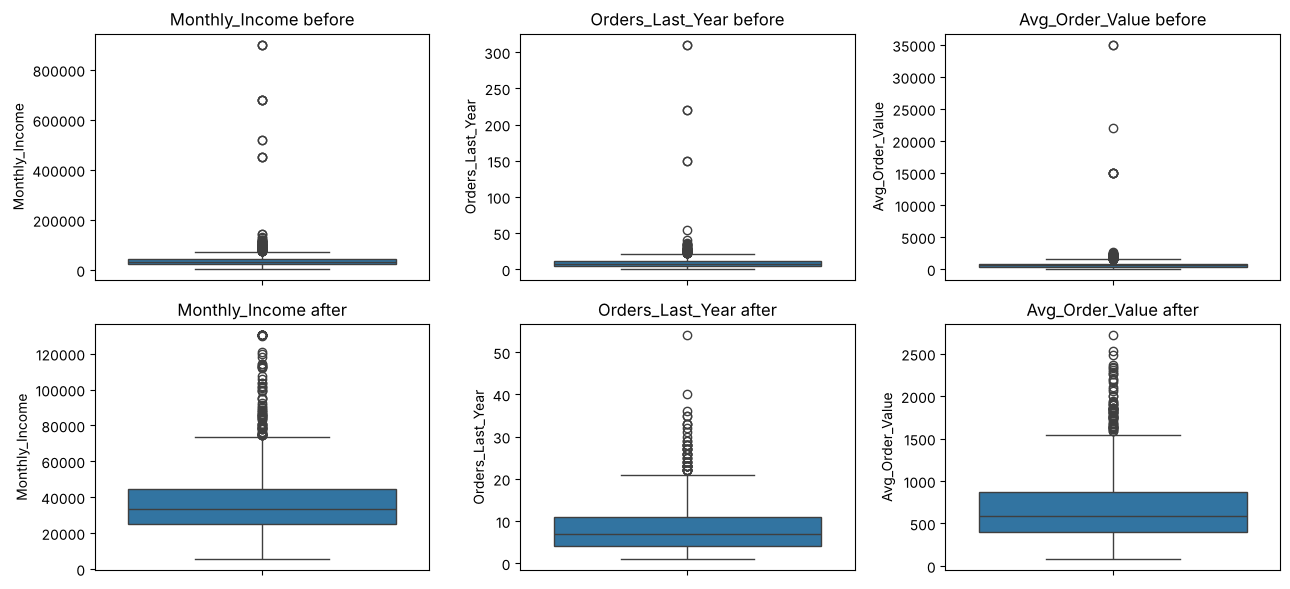

In [48]:
plt.figure(figsize=(13, 6))
for i, col in enumerate(["Monthly_Income", "Orders_Last_Year", "Avg_Order_Value"]):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=before[col]); plt.title(col + " before")
    plt.subplot(2, 3, i + 4)
    sns.boxplot(y=df[col]); plt.title(col + " after")
plt.tight_layout()
plt.show()

<div style="background:#2e7d32;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:26px;font-size:20px;font-weight:bold">Part B · Encoding the text columns</div>

## Encoding · B1 · Which columns are text?  *(pandas basics)*
A model can only use numbers, so we first find the text (categorical) columns and look at how many different values each has.

In [49]:
cat_cols = df.select_dtypes(exclude=["number"]).columns
for col in cat_cols:
    print(col, "->", df[col].nunique(), "unique values")

print()
for col in ["Gender", "Membership", "Payment_Mode", "City"]:
    print(df[col].value_counts(), "\n")

Customer_ID -> 1465 unique values
Gender -> 4 unique values
City -> 9 unique values
Membership -> 4 unique values
Payment_Mode -> 5 unique values

Gender
Female     722
Male       657
Unknown     50
Other       36
Name: count, dtype: int64 

Membership
Basic       768
Silver      385
Gold        191
Platinum    121
Name: count, dtype: int64 

Payment_Mode
UPI                 688
Cash on Delivery    251
Credit Card         238
Debit Card          203
Net Banking          85
Name: count, dtype: int64 

City
Kochi         357
Trivandrum    227
Kozhikode     206
Thrissur      173
Kollam        141
Kannur        113
Alappuzha     112
Palakkad       71
Unknown        65
Name: count, dtype: int64 



**What to notice and decide:**
| Column | Values | Type | Idea |
|---|---|---|---|
| Customer_ID | 1465 (one per row) | **Identifier** | Do not encode; drop it |
| Gender | 4 | Nominal (no order) | One-hot |
| Membership | 4 | **Ordinal** (Basic < Silver < Gold < Platinum) | Ordinal encoding with the right order |
| Payment_Mode | 5 | Nominal | One-hot |
| City | 9 | Nominal, more values | One-hot (or frequency) |

## Encoding · B2 · Is the text clean enough?
Encoders treat `Kochi` and `kochi` as two different values, and many cannot handle blanks. Our earlier cleaning (spelling fixed, blanks filled) is what makes encoding possible.

In [50]:
print(df[cat_cols].isna().sum())
print("Cities:", sorted(df["City"].unique()))
print("Membership:", sorted(df["Membership"].unique()))

Customer_ID     0
Gender          0
City            0
Membership      0
Payment_Mode    0
dtype: int64
Cities: ['Alappuzha', 'Kannur', 'Kochi', 'Kollam', 'Kozhikode', 'Palakkad', 'Thrissur', 'Trivandrum', 'Unknown']
Membership: ['Basic', 'Gold', 'Platinum', 'Silver']


## Encoding · B3 · Label encoding  *(and why it can mislead)*
`LabelEncoder` gives every value a number: 0, 1, 2 ...

In [51]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
gender_label = le.fit_transform(df["Gender"])
print({name: int(code) for name, code in zip(le.classes_, le.transform(le.classes_))})
print(gender_label[:10])

{'Female': 0, 'Male': 1, 'Other': 2, 'Unknown': 3}
[0 1 1 0 0 1 1 0 0 1]


**What to notice:** the numbers follow the alphabet: Female 0, Male 1, Other 2, Unknown 3. A model would read this as **Unknown (3) is bigger than Male (1)**, and the gap between Female and Other (2) is twice the gap between Female and Male. For `Gender` this order has **no meaning**, so label encoding is a poor choice here. Label encoding is fine for a **target** column or when the order is real.

## Encoding · B4 · Ordinal encoding for Membership
Membership has a **real order**, so the numbers must follow it. We write the order ourselves (dictionary mapping), instead of letting the alphabet decide.

In [52]:
order = {"Basic": 0, "Silver": 1, "Gold": 2, "Platinum": 3}
df["Membership_code"] = df["Membership"].map(order)
print(df[["Membership", "Membership_code"]].drop_duplicates().sort_values("Membership_code"))
print("Unmapped values:", df["Membership_code"].isna().sum())

   Membership  Membership_code
0       Basic                0
1      Silver                1
3        Gold                2
26   Platinum                3
Unmapped values: 0


In [53]:
from sklearn.preprocessing import OrdinalEncoder

oe = OrdinalEncoder(categories=[["Basic", "Silver", "Gold", "Platinum"]])
same = oe.fit_transform(df[["Membership"]]).ravel()
print("OrdinalEncoder gives the same codes:", (same == df["Membership_code"]).all())

OrdinalEncoder gives the same codes: True


In [54]:
print(df.groupby("Membership_code")["Total_Spent"].median())
print("Correlation with Total_Spent:", round(df["Membership_code"].corr(df["Total_Spent"]), 2))

Membership_code
0    2954.0
1    4107.0
2    5593.0
3    7839.0
Name: Total_Spent, dtype: float64
Correlation with Total_Spent: 0.31


**What to notice:** the median spend rises step by step with the code (0, 1, 2, 3), so the order we chose matches the data. If we had used `LabelEncoder` here it would give Basic 0, Gold 1, Platinum 2, Silver 3 (alphabetical): **wrong order**.

## Encoding · B5 · One-hot encoding for Payment_Mode
One new 0/1 column for each value. No order is created.

In [55]:
pay = pd.get_dummies(df["Payment_Mode"], prefix="Pay", dtype=int)
print(pay.head())
print("Shape:", pay.shape)
print("Every row has exactly one 1:", (pay.sum(axis=1) == 1).all())

   Pay_Cash on Delivery  Pay_Credit Card  Pay_Debit Card  Pay_Net Banking  Pay_UPI
0                     0                0               1                0        0
1                     0                0               0                0        1
2                     0                0               0                0        1
3                     0                1               0                0        0
4                     1                0               0                0        0
Shape: (1465, 5)
Every row has exactly one 1: True


**Dummy variable trap:** the 5 columns always add up to 1, so the last one is **predictable from the other four**. Dropping one (`drop_first=True`) keeps all the information and avoids this repetition.

In [56]:
pay2 = pd.get_dummies(df["Payment_Mode"], prefix="Pay", drop_first=True, dtype=int)
print(list(pay2.columns))
print("Shape:", pay2.shape)

['Pay_Credit Card', 'Pay_Debit Card', 'Pay_Net Banking', 'Pay_UPI']
Shape: (1465, 4)


## Encoding · B6 · City: more values, more options

In [57]:
print("Unique cities:", df["City"].nunique())
city_dummies = pd.get_dummies(df["City"], prefix="City", drop_first=True, dtype=int)
print("One-hot columns:", city_dummies.shape[1])

# another option: frequency encoding (replace each city by how common it is)
df["City_freq"] = df["City"].map(df["City"].value_counts(normalize=True)).round(3)
print(df[["City", "City_freq"]].drop_duplicates().sort_values("City_freq", ascending=False))

Unique cities: 9
One-hot columns: 8
          City  City_freq
3        Kochi      0.244
37  Trivandrum      0.155
0    Kozhikode      0.141
1     Thrissur      0.118
6       Kollam      0.096
20      Kannur      0.077
26   Alappuzha      0.076
10    Palakkad      0.048
25     Unknown      0.044


**What to notice:** 9 cities give 8 one-hot columns, which is fine for 1465 rows. If a column had hundreds of values (a village or pin code), one-hot would add hundreds of columns; then **frequency encoding** (one column) is the lighter choice. The price: two cities with the same frequency look the same to the model.

## Encoding · B7 · Customer_ID: a column we do not encode

In [58]:
print("Unique IDs:", df["Customer_ID"].nunique(), "| rows:", len(df))
print("One-hot columns we would get:", df["Customer_ID"].nunique())

Unique IDs: 1465 | rows: 1465
One-hot columns we would get: 1465


**What to notice:** every row has its own ID. One-hot would create **1465 columns** and the model would learn nothing general from them. An identifier is **dropped**, not encoded.

## Encoding · B8 · The final numeric table

In [59]:
df = df.drop(columns=["Membership_code", "City_freq"])      # helper columns from the experiments above

df_encoded = df.drop(columns=["Customer_ID"]).copy()
df_encoded["Membership"] = df_encoded["Membership"].map(order)
df_encoded = pd.get_dummies(df_encoded, columns=["Gender", "Payment_Mode", "City"], drop_first=True, dtype=int)

print("Shape:", df.shape, "->", df_encoded.shape)
print(list(df_encoded.columns))
print(df_encoded.head(3))

Shape: (1465, 10) -> (1465, 21)
['Age', 'Membership', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value', 'Total_Spent', 'Gender_Male', 'Gender_Other', 'Gender_Unknown', 'Payment_Mode_Credit Card', 'Payment_Mode_Debit Card', 'Payment_Mode_Net Banking', 'Payment_Mode_UPI', 'City_Kannur', 'City_Kochi', 'City_Kollam', 'City_Kozhikode', 'City_Palakkad', 'City_Thrissur', 'City_Trivandrum', 'City_Unknown']
    Age  Membership  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent  Gender_Male  Gender_Other  Gender_Unknown  Payment_Mode_Credit Card  Payment_Mode_Debit Card  \
0  29.0           0         55900.0               6.0            523.0       3143.0            0             0               0                         0                        1   
1  36.0           1         47900.0              21.0            855.0      16395.0            1             0               0                         0                        0   
2  18.0           0         32600.0             

## Encoding · B9 · Check the result

In [60]:
print("Text columns left:", list(df_encoded.select_dtypes(exclude=["number"]).columns))
print("Missing values:", int(df_encoded.isna().sum().sum()))
print(df_encoded.dtypes.value_counts())

Text columns left: []
Missing values: 0
int64      16
float64     5
Name: count, dtype: int64


## Encoding · B10 · Decisions with reasons
| Column | Type | Method | Why |
|---|---|---|---|
| Customer_ID | Identifier | Dropped | One value per row; no pattern to learn |
| Membership | Ordinal | Ordinal mapping (Basic 0 to Platinum 3) | The order is real, and median spend rises with it |
| Gender | Nominal | One-hot (`drop_first=True`) | No order; label codes would invent one |
| Payment_Mode | Nominal | One-hot (`drop_first=True`) | No order |
| City | Nominal, 9 values | One-hot (`drop_first=True`) | Few enough values; frequency encoding is the option for many values |

`df` keeps the readable text; **`df_encoded`** is the all-numeric table for the next steps.

---
## Encoding · What was in the data (answer sheet)
* 5 text columns: Customer_ID (identifier), Gender (nominal, 4 values), Membership (**ordinal**, 4 values), Payment_Mode (nominal, 5 values), City (nominal, 9 values).
* The earlier cleaning matters: before it, City had spelling variants (`kochi`, `Kochi `, `KOCHI`) and Membership had `silver`, `SILVER`; an encoder would have created extra, wrong columns. Blanks would also have caused errors.
* Alphabetical label codes put Membership in the wrong order (Gold before Silver).
* Final table: 1465 rows, 21 columns, all numbers, no missing values.

## Encoding · Check your own work
| Level | What you did |
|---|---|
| Basic | found the text columns and encoded them with `get_dummies` or `LabelEncoder` |
| Good | used the right order for Membership, one-hot for the nominal columns, dropped Customer_ID |
| Excellent | explained why label encoding misleads for Gender, used `drop_first`, checked that no text or blanks are left, compared one-hot and frequency encoding for City, wrote a reason for each column |

## Encoding · Common mistakes
* `LabelEncoder` on Gender, City or Payment_Mode (invents an order).
* Alphabetical codes for Membership (Gold before Silver).
* One-hot encoding Customer_ID (1465 columns).
* Encoding before cleaning the spelling or filling blanks.
* Forgetting `dtype=int` and getting True/False columns (works, but harder to read).
* Not saving the result (`df_encoded = ...`).

## Encoding · Think about it
1. Why does a model need numbers instead of text?
2. When is label encoding fine, and when does it mislead?
3. Why do we drop one column in one-hot encoding?
4. Which encoding would you use for a column with 500 different values, and why?

<div style="background:#6a1b9a;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:20px">End of the Session 46 · Encoding section</div>

<div style="background:#00695c;color:#ffffff;padding:18px 22px;border-radius:8px;margin-top:40px">
<div style="font-size:13px;letter-spacing:1px">NEW SECTION · SESSION 48 · CONTINUATION OF THIS NOTEBOOK</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Scaling</div>
<div style="font-size:14px;margin-top:6px">Use-Case Discussion solution · everything above this banner is the Session 42, 44 and 46 solution (Missing Values &amp; Duplicates, Outliers, Encoding)</div>
</div>

# Scaling
**ICT Academy of Kerala · Session 48 · Use-Case Discussion: Scaling · Solution (shared after submission)**

This section contains **only what was taught** in the Scaling class: **StandardScaler** and **MinMaxScaler**. Other scalers and the transformation techniques (log, power) were not taught yet, so they are not here; they will come in the next session's solution.

**How to use this section:** compare it with your own work. It shows **one good way** to explore and scale the QuickKart data. Your steps may differ. What matters is that every decision has a **reason**.

**Continue in this same notebook.** We use **`df_encoded`**, the all-numeric table from the Encoding section above. We do not repeat the earlier solutions.

**Scenario:** the team will now train a model on the QuickKart customers. The columns are on very different scales (Age is about 18 to 70, Total_Spent goes up to ₹85,000). Which columns need scaling, which scaler should we use, and why?

| Part | What it contains | Class it comes from |
|---|---|---|
| A | Why we scale, StandardScaler, MinMaxScaler, comparing the two | Scaling class |
| B | Applying the scaler, checking, decisions | Scaling class |

**Map of exploration to classes**
| Section | What is explored | Class it comes from |
|---|---|---|
| A1 | ranges of the columns, which ones to scale | descriptive statistics |
| A2 | why scale: one column dominating a distance | **today** |
| A3 | StandardScaler | **today** |
| A4 | MinMaxScaler | **today** |
| A5 | StandardScaler vs MinMaxScaler | **today** |
| A6 | scaling changes the numbers, not the shape | Matplotlib / Seaborn |
| B1 | scaling the table | **today** |
| B2 | checking the result | pandas |
| B3 | decisions with reasons | **today** |

<div style="background:#2e7d32;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:22px;font-size:20px;font-weight:bold">Part A · Understanding scaling</div>

## Scaling · A1 · How different are the scales?  *(descriptive statistics)*
First separate the **continuous** columns (real measurements) from the 0/1 dummy columns made by one-hot encoding.

In [61]:
cont_cols = ["Age", "Monthly_Income", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent"]
dummy_cols = [col for col in df_encoded.columns if col not in cont_cols + ["Membership"]]

summary = df_encoded[cont_cols].describe().T[["min", "max", "mean", "std"]]
summary["range"] = summary["max"] - summary["min"]
print(summary.round(1))
print()
print("Dummy columns:", len(dummy_cols), "| their values:", sorted(int(v) for v in df_encoded[dummy_cols[0]].unique()))

                     min       max     mean      std     range
Age                 18.0      70.0     34.2      9.5      52.0
Monthly_Income    5500.0  130248.0  38126.2  20255.7  124748.0
Orders_Last_Year     1.0      54.0      8.1      5.9      53.0
Avg_Order_Value     81.0    2717.0    690.5    405.7    2636.0
Total_Spent        157.0   85073.0   5720.8   6537.9   84916.0

Dummy columns: 15 | their values: [0, 1]


**What to notice:** the ranges are very different: Age spans 52 and Orders 53, Avg_Order_Value about 2,600, Total_Spent about 85,000 and Monthly_Income about 1.2 lakh. The 0/1 dummy columns are already on a tiny scale and `Membership` is 0 to 3.

**Decision:** scale the 5 continuous columns. Leave the dummy columns alone (scaling 0/1 gains nothing and makes them harder to read). `Membership` is a small ordered code; we leave it here and explain why in B3.

## Scaling · A2 · Why scale? One column can dominate
Many models (KNN, K-means, anything based on distance) compare customers by the distance between their rows. Take the first two customers and see which column decides that distance.

In [62]:
two = df_encoded.loc[[0, 1], cont_cols]
print(two)

diff_sq = (two.iloc[0] - two.iloc[1]) ** 2
share = (diff_sq / diff_sq.sum() * 100).round(1)
print()
print("Share of the squared distance, raw data (%):")
print(share)

    Age  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
0  29.0         55900.0               6.0            523.0       3143.0
1  36.0         47900.0              21.0            855.0      16395.0

Share of the squared distance, raw data (%):
Age                  0.0
Monthly_Income      26.7
Orders_Last_Year     0.0
Avg_Order_Value      0.0
Total_Spent         73.3
dtype: float64


In [63]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaled_two = pd.DataFrame(StandardScaler().fit(df_encoded[cont_cols]).transform(two), columns=cont_cols)
diff_sq2 = (scaled_two.iloc[0] - scaled_two.iloc[1]) ** 2
print("Share of the squared distance, after scaling (%):")
print((diff_sq2 / diff_sq2.sum() * 100).round(1).to_string())

Share of the squared distance, after scaling (%):
Age                  4.6
Monthly_Income       1.3
Orders_Last_Year    53.9
Avg_Order_Value      5.6
Total_Spent         34.6


**What to notice:** on the raw data the distance is decided only by the columns with big numbers (`Total_Spent`, `Monthly_Income`). Age and Orders count for nothing, only because their numbers are small. After scaling, the share depends on how different the two customers really are (here Orders and Total_Spent differ most), not on how big the numbers happen to be.

## Scaling · A3 · StandardScaler (standardisation)
Each value becomes **(x − mean) / standard deviation**. Result: mean 0, standard deviation 1.

In [64]:
std_scaler = StandardScaler()
X_std = pd.DataFrame(std_scaler.fit_transform(df_encoded[cont_cols]), columns=cont_cols)
print(X_std.describe().T[["mean", "std", "min", "max"]].round(2))

# the formula by hand for one column (sklearn divides by the population std, ddof=0)
col = "Age"
by_hand = (df_encoded[col] - df_encoded[col].mean()) / df_encoded[col].std(ddof=0)
print()
print("Same as the formula by hand:", np.allclose(by_hand, X_std[col]))

                  mean  std   min    max
Age               -0.0  1.0 -1.70   3.77
Monthly_Income    -0.0  1.0 -1.61   4.55
Orders_Last_Year  -0.0  1.0 -1.20   7.75
Avg_Order_Value    0.0  1.0 -1.50   5.00
Total_Spent        0.0  1.0 -0.85  12.14

Same as the formula by hand: True


**What to notice:** every column now has mean 0 and standard deviation 1. A value of 2 means "2 standard deviations above average". The extreme values are still extreme (look at the `max` of the skewed columns).

## Scaling · A4 · MinMaxScaler (normalisation)
Each value becomes **(x − min) / (max − min)**. Result: every column between 0 and 1.

In [65]:
mm_scaler = MinMaxScaler()
X_mm = pd.DataFrame(mm_scaler.fit_transform(df_encoded[cont_cols]), columns=cont_cols)
print(X_mm.describe().T[["min", "max", "mean", "50%"]].round(3))

# the formula by hand for one column
col = "Total_Spent"
by_hand = (df_encoded[col] - df_encoded[col].min()) / (df_encoded[col].max() - df_encoded[col].min())
print()
print("Same as the formula by hand:", np.allclose(by_hand, X_mm[col]))

                  min  max   mean    50%
Age               0.0  1.0  0.311  0.308
Monthly_Income    0.0  1.0  0.262  0.225
Orders_Last_Year  0.0  1.0  0.134  0.113
Avg_Order_Value   0.0  1.0  0.231  0.191
Total_Spent       0.0  1.0  0.066  0.043

Same as the formula by hand: True


**What to notice:** all columns are between 0 and 1, **but** in the skewed columns the **median is very small** (most customers are squeezed near 0) because a few big values stretch the range. MinMax is easy to read, but it is sensitive to extreme values.

## Scaling · A5 · StandardScaler or MinMaxScaler?
Compare the two on `Total_Spent`, our most stretched column.

In [66]:
col = "Total_Spent"
compare = pd.DataFrame({"StandardScaler": X_std[col].describe(), "MinMaxScaler": X_mm[col].describe()}).loc[["min", "25%", "50%", "75%", "max", "mean", "std"]]
print("Total_Spent after each scaler")
print(compare.round(2))

Total_Spent after each scaler
      StandardScaler  MinMaxScaler
min            -0.85          0.00
25%            -0.58          0.02
50%            -0.29          0.04
75%             0.23          0.08
max            12.14          1.00
mean            0.00          0.07
std             1.00          0.08


| | StandardScaler | MinMaxScaler |
|---|---|---|
| Result | mean 0, std 1 (can be negative) | between 0 and 1 |
| Outliers | keeps them far away, but the bulk is not squashed as much | one extreme value sets the max, so the bulk is squeezed near 0 |
| Good for | most models; data that is roughly bell-shaped | models that need 0 to 1 (for example neural networks); images |

**For this data** both work, but because Total_Spent has a long tail, StandardScaler spreads the typical customers better.

## Scaling · A6 · Scaling changes the numbers, not the shape
A histogram of `Total_Spent` before and after each scaler (class method: a loop with subplots).

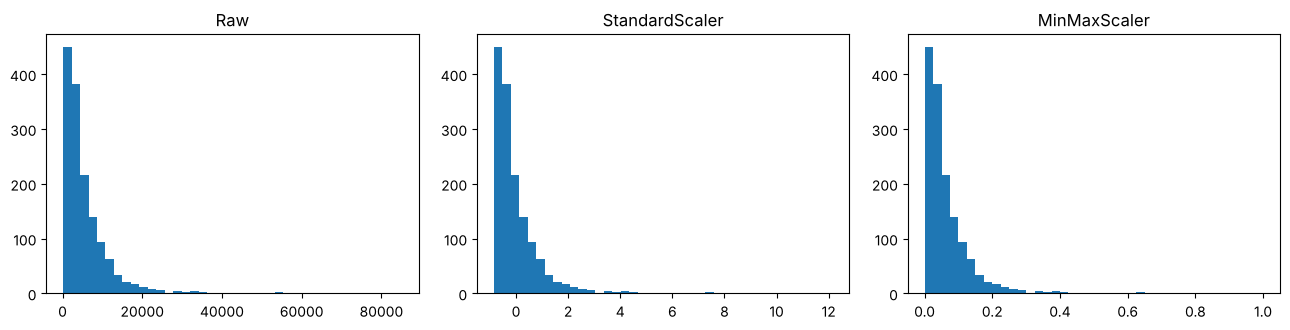

In [67]:
plot_data = {"Raw": df_encoded["Total_Spent"], "StandardScaler": X_std["Total_Spent"], "MinMaxScaler": X_mm["Total_Spent"]}

plt.figure(figsize=(13, 3.4))
for i, (name, values) in enumerate(plot_data.items(), 1):
    plt.subplot(1, 3, i)
    plt.hist(values, bins=40)
    plt.title(name)

plt.tight_layout()
plt.show()

**What to notice:** all three pictures have **the same shape**; only the numbers on the bottom axis change. Scaling puts the columns on the same scale but does not remove the long tail to the right.

<div style="background:#1a5fb4;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:22px;font-size:20px;font-weight:bold">Part B · Applying the scaler</div>

## Scaling · B1 · Scale the table
We use `StandardScaler` on the 5 continuous columns and leave the other columns as they are.

In [68]:
df_scaled = df_encoded.copy()
final_scaler = StandardScaler()
df_scaled[cont_cols] = final_scaler.fit_transform(df_scaled[cont_cols])

print("Shape:", df_encoded.shape, "->", df_scaled.shape)
print(df_scaled[cont_cols].describe().T[["mean", "std", "min", "max"]].round(2))

Shape: (1465, 21) -> (1465, 21)
                  mean  std   min    max
Age               -0.0  1.0 -1.70   3.77
Monthly_Income    -0.0  1.0 -1.61   4.55
Orders_Last_Year  -0.0  1.0 -1.20   7.75
Avg_Order_Value    0.0  1.0 -1.50   5.00
Total_Spent        0.0  1.0 -0.85  12.14


*(If you prefer 0 to 1, the same steps with `MinMaxScaler` give `df_minmax`; both are fine as long as you can explain the choice.)*

In [69]:
df_minmax = df_encoded.copy()
df_minmax[cont_cols] = MinMaxScaler().fit_transform(df_minmax[cont_cols])
print(df_minmax[cont_cols].describe().T[["min", "max"]].round(2))

                  min  max
Age               0.0  1.0
Monthly_Income    0.0  1.0
Orders_Last_Year  0.0  1.0
Avg_Order_Value   0.0  1.0
Total_Spent       0.0  1.0


## Scaling · B2 · Check the result

In [70]:
print("Missing values:", int(df_scaled.isna().sum().sum()))
print("Text columns left:", list(df_scaled.select_dtypes(exclude=["number"]).columns))
print("Dummy columns unchanged:", df_scaled[dummy_cols].equals(df_encoded[dummy_cols]))
print("Membership unchanged:", df_scaled["Membership"].equals(df_encoded["Membership"]))

Missing values: 0
Text columns left: []
Dummy columns unchanged: True
Membership unchanged: True


## Scaling · B3 · Decisions with reasons
| Column | Problem | Action | Why |
|---|---|---|---|
| Age | Different scale | StandardScaler | Needs the same footing as the others |
| Monthly_Income | Large numbers | StandardScaler | Would dominate a distance otherwise |
| Orders_Last_Year | Small numbers | StandardScaler | Same footing as the others |
| Avg_Order_Value | Medium numbers | StandardScaler | Same footing as the others |
| Total_Spent | Largest numbers, long tail | StandardScaler | Would dominate a distance; StandardScaler handles the tail better than MinMax |
| Membership (0 to 3) | Small ordered code | Not scaled here | Already on a small scale; scale it later if a model needs it |
| Dummy columns (0/1) | Already tiny | Not scaled | Scaling would only make them harder to read |

**Good practice for modelling:** the scaler should learn (`fit`) only from the **training** rows and then `transform` both train and test rows. Here we scaled the whole table to explore the scalers.

---
## Scaling · What was in the data (answer sheet)
* 5 continuous columns on very different scales (Age about 18 to 70; Total_Spent up to about ₹85,000). 15 dummy columns (0/1) and the Membership code (0 to 3).
* Without scaling, `Total_Spent` and `Monthly_Income` decide the distance between two customers; Age and Orders hardly count.
* StandardScaler gives mean 0, std 1. MinMaxScaler gives 0 to 1 but squeezes most customers near 0 in the skewed columns.
* Scaling does not change the shape of the histogram.
* Final table: 1465 rows, 21 columns, no missing values, continuous columns with mean about 0 and std 1.

## Scaling · Check your own work
| Level | What you did |
|---|---|
| Basic | scaled the continuous columns with `StandardScaler` or `MinMaxScaler` |
| Good | left the dummy columns alone, used both scalers, checked mean/std or min/max after scaling |
| Excellent | showed why scaling matters (distance), compared the two scalers on a skewed column, plotted before and after, wrote a reason for each column |

## Scaling · Common mistakes
* Scaling the 0/1 dummy columns, or the Customer_ID.
* Believing scaling removes the long tail (the shape stays the same).
* Not saving the result (`df_scaled = ...`) or scaling a column twice.
* Fitting the scaler on the test data as well (data leakage).
* Forgetting that scaled numbers are no longer rupees.

## Scaling · Think about it
1. Which models need scaling, and which do not (for example decision trees)?
2. Why is MinMaxScaler affected by one extreme value?
3. Why do we not scale the dummy columns?
4. Why should the scaler be fitted only on the training data when we build a model?

<div style="background:#00695c;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:20px">End of the Session 48 · Scaling section</div>